# 全球到 A 股资金流向监测（V1，已由 V2 替代）

> **主流程请改用** [`examples/alloc_v2/`](../alloc_v2/) 与 `./scripts/run_alloc_v2.sh`。本笔记本仅保留 V1 只读兼容。

先刷新数据（笔记本不打网）：

```bash
./scripts/run_flow_monitor.sh all --start 2018-01-01
```

**读表规则**

- **L1** 直接流量：ETF 份额、黄金 ETF 增减持、北向净买额（披露口径已变）
- **L2** 持仓/规模：必须先做价格调整，不能把市值上涨当成买入
- **L3** 代理：指数、成交额、融资、开户，只描述活跃度

价格上涨 ≠ 资金流入。成交额 ≠ 净流入。跨资产矩阵是并发配置变化的证据，**不是**已证实的资金去向。

In [14]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path("../..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from qlib.contrib.data.flow_monitor.paths_local import default_staging_root
from qlib.contrib.data.flow_monitor.report import dashboard_payload
from qlib.contrib.data.flow_monitor.staging import read_long_rows

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

DATA = default_staging_root()
print("staging:", DATA)
payload = dashboard_payload(DATA)
long_df = read_long_rows(DATA)
print("long rows:", len(long_df), "series:", 0 if long_df.empty else long_df["series_id"].nunique())

staging: /Users/900game/Desktop/ai/qlib/data/flow_staging
long rows: 163450 series: 102


In [15]:
def _plot_series(long_df, series_ids, title):
    """按序列画归一化走势，方便对照，不把涨幅解释成流入。"""
    if long_df.empty:
        print("无长表，请先 fetch")
        return
    fig, ax = plt.subplots(figsize=(10, 4))
    plotted = 0
    for sid in series_ids:
        part = long_df[long_df["series_id"] == sid].copy()
        if part.empty:
            continue
        part["date"] = pd.to_datetime(part["date"])
        part = part.sort_values("date")
        values = part["value"].astype(float)
        if values.iloc[0] == 0:
            continue
        ax.plot(part["date"], values / values.iloc[0], label=sid)
        plotted += 1
    ax.set_title(title)
    ax.set_ylabel("归一化（起点=1）")
    if plotted:
        ax.legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()

## 1. 钱从哪里出来、流向哪里？（A + B）

全球股票/债券/黄金/美元 与 中国股市、国债、黄金 ETF、货基快照并排。
先看 L1/L2 的 `chg_*`，再用 L3 的 `ret_*` 对照，不要用涨幅代替流入。

In [16]:
payload["q_source_dest"]

,layer,display_name,series_id,evidence_grade,asset_class,region,investor,freq,asof,last,ret_5d,ret_20d,chg_5d,chg_20d,notes
0,A,美国国债收益率10年,yld_us_10y,L3,bond,us,mixed,day,2026-10-30,4.940000e+00,NaN,NaN,-6.000000e-02,-3.000000e-01,
1,A,美国国债收益率2年,yld_us_2y,L3,bond,us,mixed,day,2026-10-30,4.560000e+00,NaN,NaN,-1.300000e-01,-2.400000e-01,收益率变动是定价，不是债券基金申购。
2,A,道琼斯,px_djia,L3,equity,us,mixed,day,2026-10-30,5.177031e+04,-0.008520,0.002233,-4.448516e+02,1.153594e+02,
3,A,日经225,px_n225,L3,equity,jp,mixed,day,2026-10-30,6.329011e+04,0.009522,-0.083163,5.969494e+02,-5.740811e+03,
4,A,纳斯达克综合,px_ndx,L3,equity,us,mixed,day,2026-10-30,2.543700e+04,-0.019971,-0.070495,-5.183438e+02,-1.929172e+03,东财 NDX 不通时用纳斯达克综合作 L3 代理；价格≠流入。
5,A,印度SENSEX,px_sensex,L3,equity,in,mixed,day,2026-10-30,7.445953e+04,0.018266,0.027420,1.335701e+03,1.987201e+03,
6,A,标普500,px_spx,L3,equity,us,mixed,day,2026-10-30,7.580070e+03,-0.005720,-0.029632,-4.361040e+01,-2.314702e+02,价格，不是资金流入。
7,A,欧洲斯托克50,px_sx5e,L3,equity,eu,mixed,day,2026-10-30,6.131320e+03,0.010397,-0.006813,6.309000e+01,-4.206000e+01,
8,A,SPDR黄金ETF增减持,gold_gld_change,L1,gold,global,mixed,day,2026-10-30,5.700000e-01,NaN,NaN,4.561000e+00,2.851000e+00,直接公布的增减持，优先于用市值倒推。
9,A,SPDR黄金ETF持仓,gold_gld_tonnes,L1,gold,global,mixed,day,2026-10-30,1.041653e+03,NaN,NaN,0.000000e+00,-1.147700e+01,持仓吨位变化接近黄金 ETF 投资需求；总价值变化含金价，不能直接当流入。


/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 24402 (\N{CJK UNIFIED IDEOGRAPH-5F52}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 36215 (\N{CJK UNIFIED IDEOGRAPH-8D77}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1

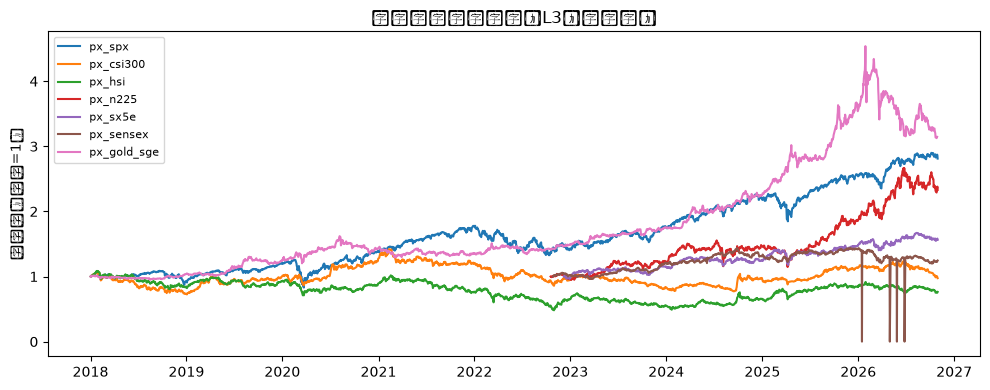

In [17]:
_plot_series(
    long_df,
    ["px_spx", "px_csi300", "px_hsi", "px_n225", "px_sx5e", "px_sensex", "px_dxy", "px_gold_sge"],
    "全球主要资产价格（L3，归一化）",
)

## 2. A 股内部去了哪些行业、风格？（C）

行业板块涨跌和成交额是 L3。同一主题的 ETF 份额才是更接近净申购的 L1。
同一只股票可能属于多个主题，板块之间不要加总。

In [18]:
payload["q_industry"]

,layer,display_name,series_id,evidence_grade,asset_class,region,investor,freq,asof,last,ret_5d,ret_20d,chg_5d,chg_20d,notes
28,C,创业板ETF成交额,etf_159915_amount,L3,equity,cn,mixed,day,2026-10-30,1.324717e+10,NaN,NaN,-6.491271e+09,5.036510e+09,成交额是双边活跃度，不是净流入。
29,C,创业板ETF收盘,etf_159915_px,L3,equity,cn,mixed,day,2026-10-30,2.435000e+00,-0.098816,-0.205287,-2.670000e-01,-6.290000e-01,价格；风格=growth。上涨不等于净申购。
30,C,创业板ETF份额,etf_159915_shares,L1,equity,cn,mixed,day,2011-12-09,3.800145e+10,NaN,NaN,NaN,NaN,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
31,C,消费ETF成交额,etf_159928_amount,L3,equity,cn,mixed,day,2026-10-30,6.093953e+08,NaN,NaN,1.179627e+08,3.152478e+08,成交额是双边活跃度，不是净流入。
32,C,消费ETF收盘,etf_159928_px,L3,equity,cn,mixed,day,2026-10-30,6.760000e-01,0.019608,0.022693,1.300000e-02,1.500000e-02,价格；风格=consumer。上涨不等于净申购。
33,C,消费ETF份额,etf_159928_shares,L1,equity,cn,mixed,day,2013-09-16,2.372663e+10,NaN,NaN,NaN,NaN,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
34,C,上证50ETF成交额,etf_510050_amount,L3,equity,cn,mixed,day,2026-10-30,2.142853e+09,NaN,NaN,-1.481317e+09,-4.179471e+08,成交额是双边活跃度，不是净流入。
35,C,上证50ETF收盘,etf_510050_px,L3,equity,cn,mixed,day,2026-10-30,2.862000e+00,-0.002440,-0.019527,-7.000000e-03,-5.700000e-02,价格；风格=large。上涨不等于净申购。
36,C,上证50ETF份额,etf_510050_shares,L1,equity,cn,mixed,day,2026-10-30,1.232167e+10,NaN,NaN,-6.714000e+08,9.315000e+08,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
37,C,中证500ETF成交额,etf_510500_amount,L3,equity,cn,mixed,day,2026-10-30,3.932526e+09,NaN,NaN,-4.898737e+09,-5.057949e+08,成交额是双边活跃度，不是净流入。


/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 24402 (\N{CJK UNIFIED IDEOGRAPH-5F52}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 36215 (\N{CJK UNIFIED IDEOGRAPH-8D77}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1

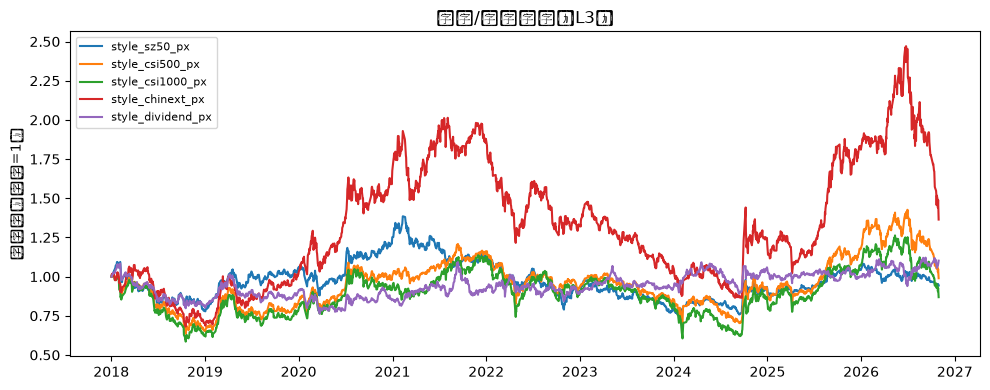

In [19]:
_plot_series(
    long_df,
    ["style_sz50_px", "style_csi500_px", "style_csi1000_px", "style_chinext_px", "style_dividend_px"],
    "市值/风格指数（L3）",
)

## 3. 谁在买？（D）

按投资者类型看，并核对 `asof` 和 `freq`。
外资用北向历史净买额时，记住披露规则已变；保险/机构持股是月或季，不能当当日资金。

In [20]:
payload["q_who"]

,layer,display_name,series_id,evidence_grade,asset_class,region,investor,freq,asof,last,ret_5d,ret_20d,chg_5d,chg_20d,notes
93,D,债券型开放式基金规模快照,fund_scale_bond_snapshot,L2,bond,cn,mutual_fund,day,2026-11-01,9.991385e+08,NaN,NaN,NaN,NaN,时点快照，不是净申购时间序列。
94,D,货币型开放式基金规模快照,fund_scale_money_snapshot,L2,cash,cn,mutual_fund,day,2026-11-01,3.494172e+08,NaN,NaN,NaN,NaN,现金层代理；快照含收益结转。
95,D,新增投资者数量,account_new,L3,equity,cn,retail,week,2023-08-01,9.959000e+01,NaN,NaN,8.560000e+00,8.560000e+00,周频活跃度，不是净买入。
96,D,股票型开放式基金规模快照,fund_scale_equity_snapshot,L2,equity,cn,mutual_fund,day,2026-11-01,4.292725e+08,NaN,NaN,NaN,NaN,个基规模加总的时点快照，不是时间序列净申购；含净值涨跌。
97,D,北向持股市值,hsgt_north_hold_mcap,L2,equity,cn,foreign,day,2026-10-30,0.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,市值含价格；估计买入请用价格调整公式。沪深港通披露口径曾调整，历史北向净买额不能当作今日完整...
98,D,北向成交净买额,hsgt_north_net,L1,equity,cn,foreign,day,2024-08-16,-6.774990e+01,NaN,NaN,9.899400e+00,-6.426340e+01,沪深港通披露口径曾调整，历史北向净买额不能当作今日完整实时外资流量；持股市值变化需剔除价格后...
99,D,机构持股家数快照,institute_hold_snapshot,L2,equity,cn,institution,quarter,2026-11-01,1.490000e+02,NaN,NaN,NaN,NaN,季报披露滞后，不能判断当日资金。
100,D,上海融资余额,margin_sh_balance,L3,equity,cn,retail_leverage,day,2026-10-29,1.218189e+12,NaN,NaN,-1.916202e+10,-7.324813e+10,融资负债变化，不等于全市场净流入相同金额。
101,D,深圳融资余额,margin_sz_balance,L3,equity,cn,retail_leverage,day,2026-10-29,1.130964e+12,NaN,NaN,-2.650736e+10,-9.948395e+10,融资负债变化，不等于全市场净流入相同金额。


## 4. 为什么流动？（并列事实，不是自动因果）

把利率、美元、黄金、中美股指放在一起看。笔记本不会下「因为加息所以流出」这类结论。

In [21]:
payload["q_why"]

,series_id,display_name,layer,asset_class,region,investor,evidence_grade,freq,unit,asof,last,n_obs,notes,chg_5d,chg_20d,chg_60d,ret_5d,ret_20d,ret_60d
0,yld_us_10y,美国国债收益率10年,A,bond,us,mixed,L3,day,pct,2026-10-30,4.94000,2208,,-0.06000,-0.30000,0.19000,NaN,NaN,NaN
1,yld_us_2y,美国国债收益率2年,A,bond,us,mixed,L3,day,pct,2026-10-30,4.56000,2208,收益率变动是定价，不是债券基金申购。,-0.13000,-0.24000,0.22000,NaN,NaN,NaN
6,px_spx,标普500,A,equity,us,mixed,L3,day,index,2026-10-30,7580.06980,2220,价格，不是资金流入。,-43.61040,-231.47020,-106.07030,-0.005720,-0.029632,-0.013800
8,gold_gld_change,SPDR黄金ETF增减持,A,gold,global,mixed,L1,day,tonne,2026-10-30,0.57000,1450,直接公布的增减持，优先于用市值倒推。,4.56100,2.85100,4.84900,NaN,NaN,NaN
13,yld_cn_10y,中国国债收益率10年,B,bond,cn,mixed,L3,day,pct,2026-10-30,1.65000,2204,,0.01000,-0.03490,-0.03830,NaN,NaN,NaN
15,cn_lpr_1y,LPR一年,B,cash,cn,mixed,L3,month,pct,2026-10-20,3.00000,493,政策利率，用于解释配置动机。,0.00000,0.00000,0.00000,NaN,NaN,NaN
20,px_csi300,沪深300,B,equity,cn,mixed,L3,day,index,2026-10-30,3985.50100,2140,,-119.82800,-331.75400,-639.58500,-0.029188,-0.076844,-0.138286
21,px_hsi,恒生指数,B,equity,hk,mixed,L3,day,index,2026-10-30,23294.41992,2172,,201.05078,-916.92969,-2272.57031,0.008706,-0.037872,-0.088887
23,fx_usdcny,美元兑人民币中间价,B,fx,cn,mixed,L3,day,cny,2026-10-30,671.38000,2141,,-0.42000,-1.92000,-6.90000,NaN,NaN,NaN
27,px_gold_sge,上海金基准价,B,gold,cn,mixed,L3,day,cny/g,2026-10-28,865.31000,2140,,2.55000,-40.37000,-130.04000,0.002956,-0.044574,-0.130648


/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 24402 (\N{CJK UNIFIED IDEOGRAPH-5F52}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 19968 (\N{CJK UNIFIED IDEOGRAPH-4E00}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/787407258.py:23: UserWarning: Glyph 36215 (\N{CJK UNIFIED IDEOGRAPH-8D77}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1

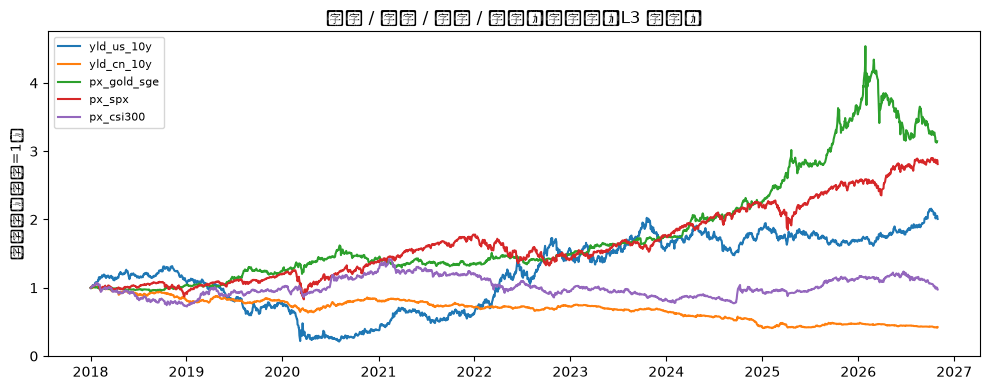

In [22]:
_plot_series(
    long_df,
    ["yld_us_10y", "yld_cn_10y", "px_dxy", "px_gold_sge", "px_spx", "px_csi300"],
    "利率 / 美元 / 黄金 / 股指（解释层，L3 为主）",
)

## 5. 资金流向是否真实？

| flag | 含义 |
|---|---|
| CONSISTENT | 价格与 L1 流量同向 |
| PRICE_DRIVEN | 涨了但流量为负或持平：更像估值/供给，不是净买入 |
| FLOW_DIVERGE | 跌了但流量为正 |
| ACTIVITY_ONLY | 只有成交额，没有 L1 |
| PRICE_ONLY | 只有价格 |

ETF 份额增加仍可能是现金申购，不等于基金管理人当天在二级市场买了等额股票。

In [23]:
payload["q_real"]

,display_name,series_id,evidence_grade,flag,price_return,level_change,flow_est,flow_proxy,amount_change,asof,notes
0,消费ETF收盘,etf_159928_px,L3,ACTIVITY_ONLY,0.022693,NaN,NaN,NaN,1.500000e-02,2013-09-16,价格；风格=consumer。上涨不等于净申购。
1,红利ETF收盘,etf_510880_px,L3,ACTIVITY_ONLY,0.008452,4.815000e+08,NaN,4.815000e+08,2.900000e-02,2026-10-30,价格；风格=dividend。上涨不等于净申购。
2,十年国债ETF收盘,etf_511260_px,L3,ACTIVITY_ONLY,0.003694,6.000000e+06,NaN,6.000000e+06,4.980000e-01,2026-10-30,价格；风格=bond。上涨不等于净申购。
3,银行ETF收盘,etf_512800_px,L3,ACTIVITY_ONLY,0.050588,3.821400e+09,NaN,3.821400e+09,4.300000e-02,2026-10-30,价格；风格=bank。上涨不等于净申购。
4,红利ETF份额,etf_510880_shares,L1,CONSISTENT,0.008452,4.815000e+08,4.824705e+08,4.815000e+08,4.572805e+08,2026-10-30,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
5,十年国债ETF份额,etf_511260_shares,L1,CONSISTENT,0.003694,6.000000e+06,-4.304622e+08,6.000000e+06,-2.176644e+09,2026-10-30,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
6,银行ETF份额,etf_512800_shares,L1,CONSISTENT,0.050588,3.821400e+09,1.500504e+08,3.821400e+09,-3.543121e+08,2026-10-30,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
7,证券ETF份额,etf_512880_shares,L1,CONSISTENT,-0.070531,-1.254000e+09,1.737000e+08,-1.254000e+09,-4.013418e+08,2026-10-30,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
8,中证红利ETF份额,etf_515080_shares,L1,CONSISTENT,0.000000,4.100000e+07,-3.299360e+08,4.100000e+07,2.116296e+07,2026-10-30,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。
9,新能源ETF份额,etf_516160_shares,L1,CONSISTENT,-0.152957,-7.750000e+07,1.661250e+07,-7.750000e+07,9.212691e+06,2026-10-30,份额增减接近净申购，但仍可能含现金申购/实物申购，不等于当日等额买股。


## 6. 并发配置变化证据矩阵

行=净减少的大类，列=净增加的大类。格子里是并发强度，**不能**写成「资金从股票流向黄金」。

In [24]:
alloc = payload["allocation"]
alloc

,window_days,disclaimer,from_asset,equity,bond,gold,cash,score_equity,score_bond,score_gold,score_cash
0,20,并发配置变化证据，不是已证实的资金去向,equity,0.000000,0.00000,0.0,0.0,28.534667,4.63017,-7.175219,0.0
1,20,并发配置变化证据，不是已证实的资金去向,bond,0.000000,0.00000,0.0,0.0,28.534667,4.63017,-7.175219,0.0
2,20,并发配置变化证据，不是已证实的资金去向,gold,7.175219,4.63017,0.0,0.0,28.534667,4.63017,-7.175219,0.0
3,20,并发配置变化证据，不是已证实的资金去向,cash,0.000000,0.00000,0.0,0.0,28.534667,4.63017,-7.175219,0.0


/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/1474463110.py:12: UserWarning: Glyph 24182 (\N{CJK UNIFIED IDEOGRAPH-5E76}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/1474463110.py:12: UserWarning: Glyph 21457 (\N{CJK UNIFIED IDEOGRAPH-53D1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/1474463110.py:12: UserWarning: Glyph 37197 (\N{CJK UNIFIED IDEOGRAPH-914D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/1474463110.py:12: UserWarning: Glyph 32622 (\N{CJK UNIFIED IDEOGRAPH-7F6E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpdg1gx1z536fvmc9p__crh0000gn/T/ipykernel_53330/1474463110.py:12: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2n/mmpd

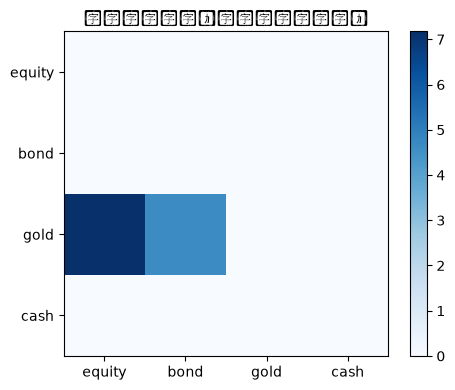

In [25]:
if not alloc.empty:
    heat_cols = [c for c in ("equity", "bond", "gold", "cash") if c in alloc.columns]
    heat = alloc.set_index("from_asset")[heat_cols]
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(heat.values, cmap="Blues")
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)
    ax.set_title("并发配置证据（非资金迁移证明）")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

## 未取到的序列

`disabled` 是本期没有稳定免费接口（如 ICI）。`missing` 是接口失败或区间内无数据，不要把空图当成零流入。

In [26]:
payload["unavailable"][["series_id", "display_name", "evidence_grade", "status", "notes"]]

,series_id,display_name,evidence_grade,status,notes
0,px_dxy,美元指数,L3,missing,美元强弱，用于解释跨境配置，本身不是资金流。
1,px_crb,CRB商品指数,L3,missing,
2,ici_mmf_aum,ICI美国货币基金规模,L1,disabled,ICI 周报暂无稳定自动接口，现金层改看利率与国内货基规模。
3,us_etf_tlt_shares,TLT份额,L1,disabled,美债 ETF 份额需独立源，本期未接入。
4,insurance_income,原保险保费收入,L2,missing,月频保费，不是股票配置；保险资金运用余额另需银保监口径。
5,pboc_gold_fx,央行黄金与外汇储备,L2,missing,官方储备存量，含估值，需结合公布口径解读。
6,cn_m2,中国M2,L3,missing,货币环境，不是证券市场净流入。
7,ind_semiconductor_px,半导体板块收盘,L3,missing,东财行业口径；指数上涨不等于行业净流入。
8,ind_semiconductor_amount,半导体板块成交额,L3,missing,成交额上升只说明交易活跃。
